In [18]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
from pathlib import Path
from scipy.optimize import least_squares
from scipy.optimize import curve_fit
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from iminuit import Minuit

In [19]:
def readfile(fpath):
    with h5py.File(fpath, "r") as f:
        S_complesso = np.array(f["band/S_complex"])
        freq = np.array(f["band/frequency_Hz"])
        volt = np.array(f["band/voltage_V"])
    return S_complesso, freq, volt

In [20]:
#E.1 Gao --> trasmissione complesso S21(f) 
#aggiunto fondo polinomiale complesso
#aggiunta correzione preliminare del ritardo dei cavi
#con incerteza su f0

def modello_base(parametri, frequenza_GHz):
    (
        Qr, Qc, phi0, f0,   #parametri risonanza
        a0_re, a0_im,       #parametri fondo complesso
        a1_re, a1_im,
        #a2_re, a2_im,
        #a3_re, a3_im,
    ) = parametri

    a0 = a0_re + 1j * a0_im
    a1 = a1_re + 1j * a1_im
    #a2 = a2_re + 1j * a2_im
    #a3 = a3_re + 1j * a3_im

    x = (frequenza_GHz - f0) / f0               #normalizzo la frequenza (scostamento dalla freq di risonanza)
    C = a0 + a1 * x #+ a2 * x**2 + a3 * x**3     #modello del fondo

    termine_ris = 1 - (                         #modello risonanza
        (Qr / Qc) * np.exp(1j * phi0)
        / (1 + 2j * Qr * x)
    )

    return C * termine_ris

def residui_base(par, freq_GHz, dati):          #concateno le 2 componenti per conservare info complessa
    differenza = modello_base(par, freq_GHz) - dati

    return np.concatenate([
        differenza.real,
        differenza.imag
    ])


def fit_base(S_complesso, freq):
    S_complesso = np.asarray(S_complesso, dtype=complex)
    freq_GHz = np.asarray(freq, dtype=float) / 1e9
    S_modulo = np.abs(S_complesso)

    #STIMA f0
    f0_0 = freq_GHz[np.argmin(S_modulo)]        # stima f0, prendo il minimo di S_modulo

    n_edge = len(freq_GHz) // 10                                # numero di punti che stanno nel 10%
    ind_sx = np.arange(n_edge)                                  # 10% di punti a sx
    ind_dx = np.arange(len(freq_GHz) - n_edge, len(freq_GHz))   # 10% di punti a dx

    #STIMA TAU
    tau_stime = []
    sigma_tau_stime = []

    for indice in (ind_sx, ind_dx):
        fase = np.unwrap(np.angle(S_complesso[indice]))
        coeff, cov = np.polyfit(freq_GHz[indice], fase, 1, cov=True)

        pendenza = coeff[0]
        sigma_pendenza = np.sqrt(cov[0, 0])

        tau_stime.append(-pendenza / (2 * np.pi))
        sigma_tau_stime.append(sigma_pendenza / (2 * np.pi))

    tau_ns = np.median(tau_stime)

    # Con due stime, la mediana equivale alla loro media.
    # Propago gli errori assumendo indipendenti le due stime ai bordi.
    sigma_tau_ns = 0.5 * np.hypot(*sigma_tau_stime)

    #CORREGGO S
    S_corretto = S_complesso * np.exp(                          #correggo eliminando il ritardo stimato
        2j * np.pi * freq_GHz * tau_ns
    )

    #STIMA a0
    ind_bordo = np.concatenate([ind_sx, ind_dx])
    a0 = np.mean(S_corretto[ind_bordo])             #val iniziale di a0 lo prendo come media di S ai bordi





    #PARAMETRI INIZIALI
    parametri_iniziali = [
        5000.0,       # Qr
        10000.0,      # Qc
        0.0,          # phi0
        f0_0,         # f0 [GHz]
        a0.real,      # a0 reale
        a0.imag,      # a0 immaginario
        0.0, 0.0,     # a1 reale e immaginario
    #    0.0, 0.0,     # a2 reale e immaginario
    #    0.0, 0.0,     # a3 reale e immaginario
    ]

    #LIMITI AI PARAMETRI
    limiti_inferiori = [
        1.0, 1.0, -np.pi, freq_GHz.min(),
        #*([-np.inf] * 8),
        *([-np.inf] * 4),
    ]
    limiti_superiori = [
        1e7, 1e10, np.pi, freq_GHz.max(),
        #*([np.inf] * 8),
        *([np.inf] * 4),
        
    ]

    # DATI DEL FIT
    dati_fit = np.concatenate((S_corretto.real, S_corretto.imag))
    x_fit = np.arange(dati_fit.size)

    def modello_reale(_, *parametri):
        z = modello_base(parametri, freq_GHz)
        return np.concatenate((z.real, z.imag))


    parametri_fit, covarianza_fit = curve_fit(
        modello_reale,
        x_fit,
        dati_fit,
        p0=parametri_iniziali,
        bounds=(limiti_inferiori, limiti_superiori),
        method="trf",
        max_nfev=10000,
    )

    Qr_fit, Qc_fit, phi0_fit, f0_fit = parametri_fit[:4]
    S_fit = np.abs(modello_base(parametri_fit, freq_GHz))

    varianze = np.diag(covarianza_fit)
    errori_parametri = np.sqrt(np.where(varianze >= 0, varianze, np.nan))
    
    return (
        f0_fit, Qr_fit, Qc_fit, freq, S_modulo, S_fit,
        tau_ns, sigma_tau_ns, parametri_fit, errori_parametri,
        covarianza_fit
    )

Qr = 2918.07 ± 4.6
Qc = 6716.45 ± 7.9
phi0 = 0.24463 ± 0.0012
f0 = 6.96169 ± 1.9e-06
a0_re = -0.00530881 ± 6.8e-07
a0_im = -0.00328614 ± 6.8e-07
a1_re = 0.0522396 ± 0.00021
a1_im = -0.0730873 ± 0.00021
tau = 66.27 ± 0.012 ns


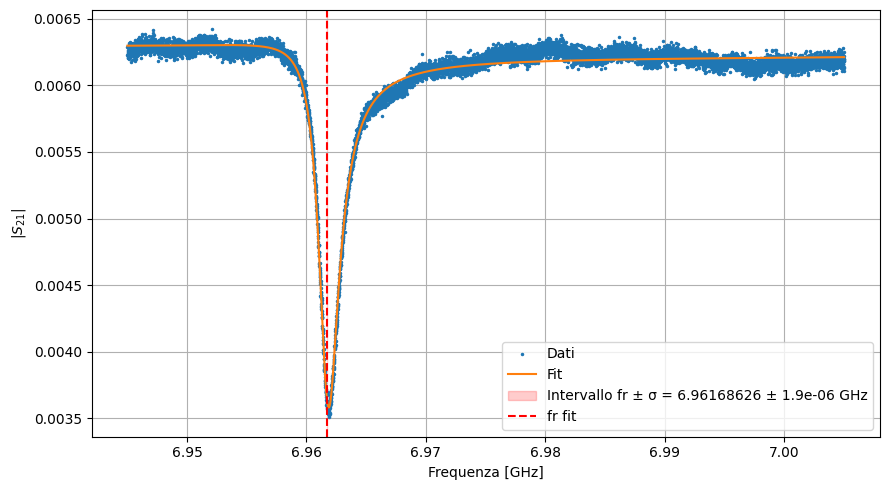

In [21]:
fpath = (
    Path(r"C:\Users\loric\Desktop\Unimib\Tesi\Misure")
    / "misure_tutte"
    / "misure_14_10"
    / "autoscan_ok"
    / "Vbias_7.000V"
    / "Run1_V7.00.h5"
)

S_complesso, freq, volt = readfile(fpath)

(
    fr_fit, Qr_fit, Qc_fit, freq, S_mod, S_fit,
    tau_ns, sigma_tau_ns, parametri_fit, errori_parametri,
    covarianza_fit
) = fit_base(S_complesso, freq)

sigma_fr_GHz = errori_parametri[3]

nomi_parametri = (
    "Qr", "Qc", "phi0", "f0",
    "a0_re", "a0_im",
    "a1_re", "a1_im",
    #"a2_re", "a2_im",
    #"a3_re", "a3_im",
)

for nome, valore, errore in zip(nomi_parametri, parametri_fit, errori_parametri):
    print(f"{nome} = {valore:.6g} ± {errore:.2g}")

print(f"tau = {tau_ns:.4g} ± {sigma_tau_ns:.2g} ns")


plt.figure(figsize=(9, 5))
plt.plot(freq / 1e9, S_mod, ".", markersize=3, label="Dati")
plt.plot(freq / 1e9, S_fit, "-", label="Fit")
plt.xlabel("Frequenza [GHz]")
plt.ylabel(r"$|S_{21}|$")
plt.axvspan(
    fr_fit - sigma_fr_GHz,
    fr_fit + sigma_fr_GHz,
    color="red",
    alpha=0.2,
    label=f"Intervallo fr ± σ = {fr_fit:.8f} ± {sigma_fr_GHz:.2g} GHz"
)
plt.axvline(fr_fit, color="red", linestyle="--", label="fr fit")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



MATRICE DI COVARIANZA:
[[ 2.115e+01  2.789e+01  7.781e-05  2.304e-09  5.965e-07  8.672e-07
   1.235e-05 -2.772e-04]
 [ 2.789e+01  6.300e+01 -1.919e-06  2.207e-07  9.791e-07  1.843e-06
   1.116e-04 -6.133e-04]
 [ 7.781e-05 -1.919e-06  1.396e-06 -1.698e-09  2.620e-10 -1.278e-10
  -9.133e-08 -1.657e-08]
 [ 2.304e-09  2.207e-07 -1.698e-09  3.533e-12 -3.279e-13  2.068e-13
   1.134e-10  4.975e-12]
 [ 5.965e-07  9.791e-07  2.620e-10 -3.279e-13  4.625e-13  5.272e-15
  -9.200e-11 -1.261e-11]
 [ 8.672e-07  1.843e-06 -1.278e-10  2.068e-13  5.272e-15  4.629e-13
   1.147e-11 -9.290e-11]
 [ 1.235e-05  1.116e-04 -9.133e-08  1.134e-10 -9.200e-11  1.147e-11
   4.501e-08 -1.317e-12]
 [-2.772e-04 -6.133e-04 -1.657e-08  4.975e-12 -1.261e-11 -9.290e-11
  -1.317e-12  4.501e-08]]


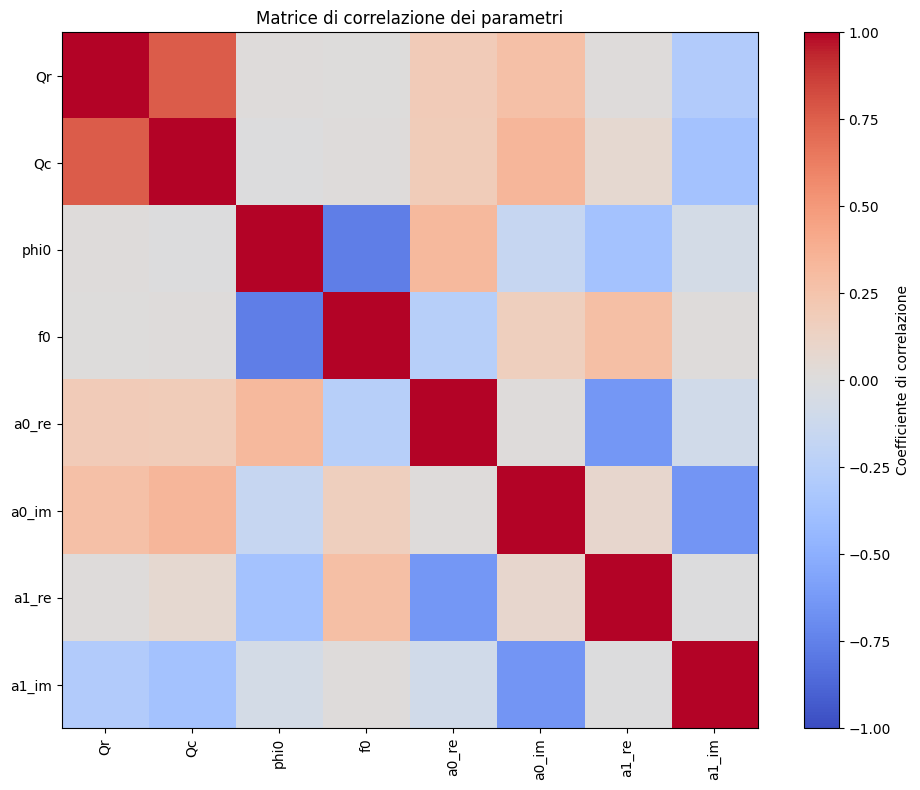


PARAMETRI E INCERTEZZE:
Qr      =  2.918071e+03 ± 4.598e+00 (0.16 %)
Qc      =  6.716451e+03 ± 7.937e+00 (0.12 %)
phi0    =  2.446302e-01 ± 1.182e-03 (0.48 %)
f0      =  6.961686e+00 ± 1.880e-06 (0.00 %)
a0_re   = -5.308810e-03 ± 6.801e-07 (0.01 %)
a0_im   = -3.286144e-03 ± 6.803e-07 (0.02 %)
a1_re   =  5.223958e-02 ± 2.122e-04 (0.41 %)
a1_im   = -7.308727e-02 ± 2.121e-04 (0.29 %)

CORRELAZIONI CON |r| > 0.9:


In [24]:
nomi_parametri = [
    "Qr", "Qc", "phi0", "f0",
    "a0_re", "a0_im",
    "a1_re", "a1_im",
    #"a2_re", "a2_im",
    #"a3_re", "a3_im"
]

# MATRICE DI COVARIANZA
print("MATRICE DI COVARIANZA:")
print(np.array2string(covarianza_fit, precision=3, suppress_small=False))

# MATRICE DI CORRELAZIONE
sigma = np.sqrt(np.diag(covarianza_fit))

denominatore = np.outer(sigma, sigma)

correlazione = np.divide(
    covarianza_fit,
    denominatore,
    out=np.full_like(covarianza_fit, np.nan),
    where=denominatore > 0
)

# GRAFICO MATRICE DI CORRELAZIONE
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(correlazione, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(8))
ax.set_yticks(range(8))

ax.set_xticklabels(nomi_parametri, rotation=90)
ax.set_yticklabels(nomi_parametri)

plt.colorbar(im, ax=ax, label="Coefficiente di correlazione")

plt.title("Matrice di correlazione dei parametri")
plt.tight_layout()
plt.show()

# INCERTEZZE RELATIVE
print("\nPARAMETRI E INCERTEZZE:")

for nome, valore, errore in zip(
    nomi_parametri, parametri_fit, sigma
):
    if valore != 0:
        errore_rel = abs(errore / valore) * 100
    else:
        errore_rel = np.nan

    print(
        f"{nome:7s} = {valore: .6e} "
        f"± {errore:.3e} "
        f"({errore_rel:.2f} %)"
    )

# COPPIE DI PARAMETRI FORTEMENTE CORRELATI
print("\nCORRELAZIONI CON |r| > 0.9:")

for i in range(12):
    for j in range(i + 1, 8):

        r = correlazione[i, j]

        if np.isfinite(r) and abs(r) > 0.9:
            print(
                f"{nomi_parametri[i]} - "
                f"{nomi_parametri[j]}: r = {r:.4f}"
            )